In [6]:
import numpy as np
from matplotlib import pyplot as plt
import wandb

In [7]:
api = wandb.Api()
runs = api.runs('julian-zim-uni-vie/hgm sep 2025-09-03 18h46 DATASET 0-2023-11-30_13-58_wt_worm3_FM-2023-11-30_no_image_data')

In [8]:
sorted_runs = sorted(runs, key=lambda run: run.summary.get('mse_loss', float('inf')))
best_runs = sorted_runs[:100]

print('ids:\n', [run.id for run in best_runs], '\n')

print(f'avg score:    {np.mean(np.array([run.summary['score'] for run in best_runs])):.6f}')
print(f'avg mpe_loss: {np.mean(np.array([run.summary['mpe_loss'] for run in best_runs])):.6f}\n')

for key in best_runs[0].config.keys():
	print(f'avg {key}: {np.mean(np.array([run.config[key] for run in best_runs])):.5f}')

print('\nconfigs:')
for run in best_runs:
	print([f'{key}: {run.config[key]:.9f}' for key in run.config.keys()])

ids:
 ['6e2vsl7l', 'jofbpwgg', 'lt2zuxry', 'k6iept7j', '1v9ms5pq', 'ij2txb9y', 'f1ebmrmd', '03jm2blh', 'x5lpkwmd', 'ks94d9cv', 'mg2qrjqk', 'pbbz7vj7', 'n694565h', 'ul7bv6mn', 'vad39hci', 'g0moki4i', '4c6wc87s', '9qedi61p', 'fpg8lo5s', 's418xotd', 'rsbkhglf', 'o4vp3obu', '42b622u2', '5thlgfie', 'kex2vezq', 'qj07qx8e', 'si6vz0jb', 'i2i5lqb4', 'hufkeri2', 'sa5qj6c5', 'lzzi3wdc', 'cjc6f76q', 'fv5ndljx', '9inm7ycw', 'zaan4269', 'furv9tk3', 'v9ixz2m7', '9xzjq01p', '33labers', 'itf4th70', '467lh0v6', 'pxchixva', 'zjb4nis7', 'h73soacu', 'e4app9tj', 'bh8bpprs', '2n1atmhb', '07opd0uq', 'm11mpzuw', 'v3n0jg1z', 'yn7g61ay', 'p2z8hvbf', 'u2gkubp7', 'jh9vb02x', 'tog2nekh', 't6sr0cu2', 'r774xhw6', 'srttcn45', 'df2yb27c', 'noktrnio', 'w7aaifs3', 'ysvwjphw', '0yjbl68n', 'bhr7e9a5', '23gy0kix', '44yzphcd', 'yo0ryud5', 'x3tr8toc', '781tnya5', 'zb06frxi', '4b4ju5ra', 'e9nv2ygr', '8xkm915j', 'v796uvyv', 't0cat857', 'foom8oif', '4qpv1lsc', '9cv0hc5t', 'hrjfg746', '1p01rcif', 'qb1qfnh0', 'wsnq2oz2', 'km68shyd

In [9]:
best_configs = [list(), list(), list()]
for run in best_runs:
	best_configs[0].append(run.config['learning_rate'])
	best_configs[1].append(run.config['w1_reg_lambda'])
	best_configs[2].append(run.config['w2_reg_lambda'])

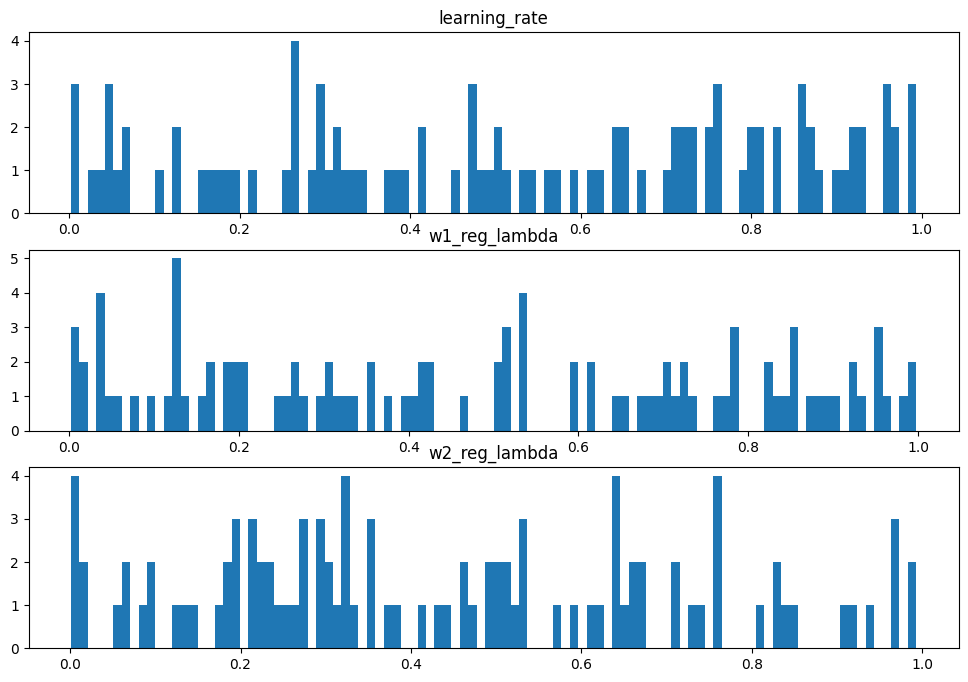

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8))

titles = ['learning_rate', 'w1_reg_lambda', 'w2_reg_lambda']
for i in range(3):
	axes[i].hist(best_configs[i], bins=100)
	axes[i].set_title(titles[i])

pass